# Colab — ChickenDet + RT-DETRv2 RESMI (PBL Monitoring Kesehatan Ayam)

**Ini notebook perbaikan, bukan notebook Ultralytics sebelumnya.** Notebook lama gagal memuat RT-DETRv2 karena Ultralytics tidak menyediakan file `rtdetrv2-s.pt` — yang jalan malah RT-DETR v1-L.

Notebook ini memakai **repo resmi RT-DETRv2** (`lyuwenyu/RT-DETR`, folder `rtdetrv2_pytorch`), config `rtdetrv2_r18vd_120e_coco.yml` (varian S, backbone ResNet18, COCO AP 48.1), dan **tuning** dari checkpoint COCO resmi `rtdetrv2_r18vd_120e_coco_rerun_48.1.pth`. Mode tuning memuat weight yang cocok dan melewati head klasifikasi 80 kelas yang bentuknya beda, jadi head 1 kelas ayam diinisialisasi baru — itu normal dan akan tercetak sebagai `unmatched`.

**Perbaikan penting vs dataset asli:** semua anotasi ChickenDet bertanda `iscrowd=1`. Kode dataset resmi membuang anotasi `iscrowd=1`, jadi kalau tidak diperbaiki, training akan jalan dengan 0 box. Cell 4 mengubah `iscrowd` jadi 0 (bbox tidak diubah sama sekali) dan menyimpannya sebagai file `_fixed.json`. Kategori tetap id 1 (Chicken), dipetakan ke label 0 lewat `remap_mscoco_category=True`, persis seperti pemetaan COCO resmi.

**Tujuan notebook ini saja:** melatih deteksi ayam dari ChickenDet. Bukan ChickenAct, bukan perilaku, bukan Kotlin, bukan VPS. Satu tugas, sampai jadi `best.pth`.

Dataset: ChickenVerse, ChickenDet — 6.539 gambar / 153.764 instance, format COCO, lisensi CC BY-NC-SA 4.0. Split resmi: train 5.222, val 1.067, test 250 (test hanya evaluasi akhir, jangan dipakai training).

**Cara pakai:**
1. Runtime > Change runtime type > T4 GPU.
2. Run All, dari atas ke bawah, jangan loncat.
3. Checkpoint disalin ke Drive tiap ~2 menit SELAMA training (thread sync di cell training), jadi kalau sesi putus, `last.pth` terakhir tetap ada di Drive dan sesi berikutnya bisa resume dari situ — bukan dari nol. Resume resmi memakai flag `-r last.pth`, bukan `-t` (tuning hanya untuk checkpoint COCO awal).
4. Setelah selesai, `best.pth` ada di Drive: `PBL-Ayam/runs/chickendet_rtdetrv2_s_official/best.pth`.

Perkiraan waktu: training 50 epoch di T4 untuk model 20M params ini lebih ringan dari v1-L kemarin (32,8M params), jadi seharusnya lebih cepat dari ~6 menit/epoch kemarin. Jangan patokan angka itu sampai epoch 1 selesai dan waktunya terlihat di log.


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
# 0. Cek GPU + mount Drive
import torch, os
print('torch:', torch.__version__)
print('CUDA tersedia:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('PERINGATAN: GPU tidak terdeteksi. Aktifkan Runtime > Change runtime type > T4 GPU, lalu run ulang.')

from google.colab import drive
drive.mount('/content/drive')
print('Drive termount di /content/drive')


torch: 2.14.1+cu130
CUDA tersedia: True
GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive termount di /content/drive


In [14]:
# 1. Konfigurasi — ubah hanya di sini kalau perlu
EPOCHS = 50
RUN_NAME = 'chickendet_rtdetrv2_s_official'  # folder run BARU, bersih dari checkpoint v1-L kemarin
PRETRAINED_URL = 'https://github.com/lyuwenyu/storage/releases/download/v0.2/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth'
REPO_URL = 'https://github.com/lyuwenyu/RT-DETR.git'
DRIVE_ROOT = '/content/drive/MyDrive/PBL-Ayam'
DRIVE_DATASET_DIR = f'{DRIVE_ROOT}/dataset'
DRIVE_RUNS_DIR = f'{DRIVE_ROOT}/runs'
LOCAL_ROOT = '/content/chickendet_work'
LOCAL_ZIP = f'{LOCAL_ROOT}/ChickenDet.zip'
DRIVE_ZIP = f'{DRIVE_DATASET_DIR}/ChickenDet.zip'
EXTRACT_DIR = f'{LOCAL_ROOT}/ChickenDet'
REPO_DIR = '/content/RT-DETR/rtdetrv2_pytorch'
CONFIG = f'{REPO_DIR}/configs/rtdetrv2/rtdetrv2_r18vd_120e_coco.yml'
PRETRAINED = '/content/rtdetrv2_s_pretrained.pth'
LOCAL_OUTPUT = f'/content/rtdetrv2_output/{RUN_NAME}'
DRIVE_RUN_DIR = f'{DRIVE_RUNS_DIR}/{RUN_NAME}'

import os
os.makedirs(DRIVE_DATASET_DIR, exist_ok=True)
os.makedirs(DRIVE_RUNS_DIR, exist_ok=True)
os.makedirs(LOCAL_ROOT, exist_ok=True)
os.makedirs(DRIVE_RUN_DIR, exist_ok=True)
print('DRIVE_ZIP :', DRIVE_ZIP)
print('LOCAL_ZIP :', LOCAL_ZIP)
print('EXTRACT_DIR:', EXTRACT_DIR)
print('CONFIG    :', CONFIG)
print('LOCAL_OUTPUT:', LOCAL_OUTPUT)
print('DRIVE_RUN_DIR:', DRIVE_RUN_DIR)


DRIVE_ZIP : /content/drive/MyDrive/PBL-Ayam/dataset/ChickenDet.zip
LOCAL_ZIP : /content/chickendet_work/ChickenDet.zip
EXTRACT_DIR: /content/chickendet_work/ChickenDet
CONFIG    : /content/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r18vd_120e_coco.yml
LOCAL_OUTPUT: /content/rtdetrv2_output/chickendet_rtdetrv2_s_official
DRIVE_RUN_DIR: /content/drive/MyDrive/PBL-Ayam/runs/chickendet_rtdetrv2_s_official


In [15]:
# 2. Dataset: zip sudah ada di Drive, salin ke lokal (jangan download ulang 4 GB)
import os, shutil
print('Target zip Drive:', DRIVE_ZIP, os.path.exists(DRIVE_ZIP), os.path.getsize(DRIVE_ZIP) if os.path.exists(DRIVE_ZIP) else 0, 'byte')
assert os.path.exists(DRIVE_ZIP) and os.path.getsize(DRIVE_ZIP) > 3_000_000_000, 'Zip ChickenDet tidak ditemukan di Drive. Cek PBL-Ayam/dataset/ChickenDet.zip.'
if not (os.path.exists(LOCAL_ZIP) and os.path.getsize(LOCAL_ZIP) == os.path.getsize(DRIVE_ZIP)):
    print('Menyalin zip dari Drive ke /content...')
    shutil.copyfile(DRIVE_ZIP, LOCAL_ZIP)
else:
    print('Salinan lokal sudah ada.')
print('Siap unzip:', LOCAL_ZIP, os.path.getsize(LOCAL_ZIP), 'byte')


Target zip Drive: /content/drive/MyDrive/PBL-Ayam/dataset/ChickenDet.zip True 3974629604 byte
Salinan lokal sudah ada.
Siap unzip: /content/chickendet_work/ChickenDet.zip 3974629604 byte


In [16]:
# 3. Unzip + kenali struktur asli dataset
import zipfile, os, json, pathlib
if not os.path.exists(EXTRACT_DIR) or len(list(pathlib.Path(EXTRACT_DIR).rglob('*.jpg'))) < 100:
    print('Unzip dimulai...')
    with zipfile.ZipFile(LOCAL_ZIP) as z:
        z.extractall(EXTRACT_DIR)
    print('Unzip selesai.')
else:
    print('Folder hasil unzip sudah ada, dilewati.')
for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, '').count(os.sep)
    if level <= 2:
        print(root, '| dirs:', dirs[:10], '| files:', len(files))
    if level > 2:
        dirs[:] = []
print()
for p in sorted(pathlib.Path(EXTRACT_DIR).rglob('*.json')):
    try:
        with open(p) as f:
            d = json.load(f)
        if isinstance(d, dict) and 'images' in d and 'annotations' in d:
            print(str(p), 'images:', len(d['images']), 'ann:', len(d['annotations']), 'cats:', d.get('categories'))
    except Exception as e:
        print('Gagal baca', p, e)


Folder hasil unzip sudah ada, dilewati.
/content/chickendet_work/ChickenDet | dirs: ['annotations', 'images'] | files: 0
/content/chickendet_work/ChickenDet/annotations | dirs: [] | files: 5
/content/chickendet_work/ChickenDet/images | dirs: ['Validation', 'Test', 'Train'] | files: 0
/content/chickendet_work/ChickenDet/images/Validation | dirs: [] | files: 1067
/content/chickendet_work/ChickenDet/images/Test | dirs: [] | files: 250
/content/chickendet_work/ChickenDet/images/Train | dirs: [] | files: 5222

/content/chickendet_work/ChickenDet/annotations/instances_Test.json images: 250 ann: 12620 cats: [{'id': 1, 'name': 'Chicken', 'supercategory': ''}]
/content/chickendet_work/ChickenDet/annotations/instances_Train.json images: 5222 ann: 116329 cats: [{'id': 1, 'name': 'Chicken', 'supercategory': ''}]
/content/chickendet_work/ChickenDet/annotations/instances_Train_fixed.json images: 5222 ann: 116329 cats: [{'id': 1, 'name': 'Chicken', 'supercategory': ''}]
/content/chickendet_work/Chick

In [17]:
# 4. PERBAIKAN WAJIB: iscrowd 1 -> 0, tanpa mengubah bbox / kategori / gambar
# Alasan: kode dataset resmi membuang anotasi iscrowd=1. Semua anotasi ChickenDet
# bertanda iscrowd=1, jadi tanpa perbaikan ini training akan jalan dengan 0 box.
# File asli TIDAK diubah, hasilnya disimpan sebagai *_fixed.json di folder annotations.
import json, os, collections, pathlib
ann_dir = os.path.join(EXTRACT_DIR, 'annotations')
fixed = {}
for name in ('instances_Train.json', 'instances_Validation.json'):
    src = os.path.join(ann_dir, name)
    dst = os.path.join(ann_dir, name.replace('.json', '_fixed.json'))
    with open(src) as f:
        d = json.load(f)
    before = collections.Counter(a.get('iscrowd') for a in d['annotations'])
    for a in d['annotations']:
        a['iscrowd'] = 0
    after = collections.Counter(a.get('iscrowd') for a in d['annotations'])
    with open(dst, 'w') as f:
        json.dump(d, f)
    fixed[name] = dst
    print(name, 'images:', len(d['images']), 'ann:', len(d['annotations']), 'cats:', d['categories'])
    print('  iscrowd sebelum:', dict(before), '-> sesudah:', dict(after))
    print('  file perbaikan:', dst, os.path.getsize(dst), 'byte')
    assert len(d['annotations']) > 0
    assert all(a['iscrowd'] == 0 for a in d['annotations'])
print('FIX SELESAI. Lanjut hanya kalau angka di atas masuk akal: Train 5222/116329, Validation 1067/24815.')


instances_Train.json images: 5222 ann: 116329 cats: [{'id': 1, 'name': 'Chicken', 'supercategory': ''}]
  iscrowd sebelum: {1: 116329} -> sesudah: {0: 116329}
  file perbaikan: /content/chickendet_work/ChickenDet/annotations/instances_Train_fixed.json 165482988 byte
instances_Validation.json images: 1067 ann: 24815 cats: [{'id': 1, 'name': 'Chicken', 'supercategory': ''}]
  iscrowd sebelum: {1: 24815} -> sesudah: {0: 24815}
  file perbaikan: /content/chickendet_work/ChickenDet/annotations/instances_Validation_fixed.json 32732465 byte
FIX SELESAI. Lanjut hanya kalau angka di atas masuk akal: Train 5222/116329, Validation 1067/24815.


Gambar train: 5222 dengan anotasi: 5219
Contoh: /content/chickendet_work/ChickenDet/images/Train/fD16_S20231125190206_E20231125191041_0069.jpg ada: True box: 11


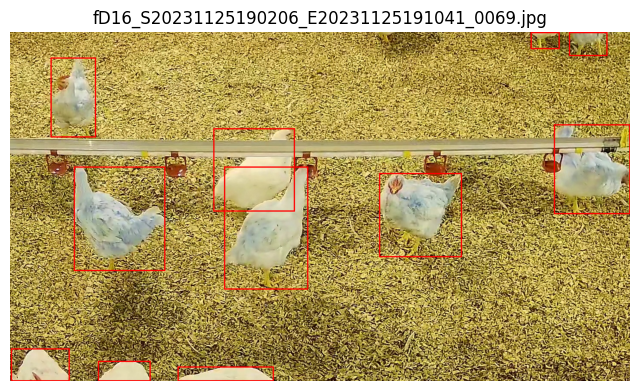

Contoh: /content/chickendet_work/ChickenDet/images/Train/fD13_S20231121150436_E20231121151311_0161.jpg ada: True box: 29


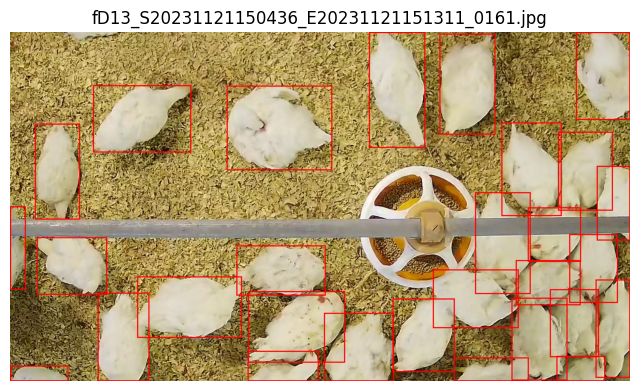

Contoh: /content/chickendet_work/ChickenDet/images/Train/fD6_S20240123113410_E20240123114244_cropped_0054.jpg ada: True box: 9


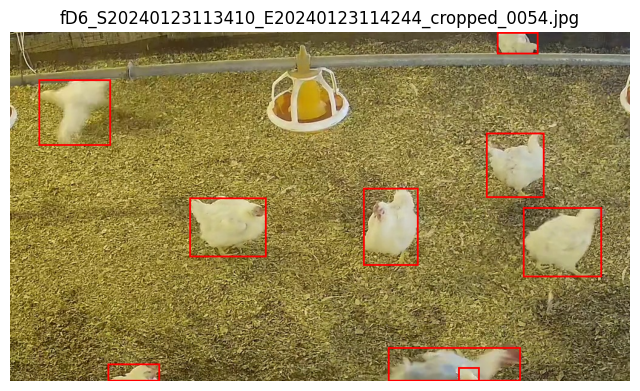

Kalau box merah menutupi ayam dengan benar, lanjut ke training. Kalau tidak, berhenti dulu.


In [18]:
# 5. Cek visual: 3 gambar train + box COCO langsung (bukan YOLO)
# Ini membuktikan file _fixed.json masih menunjuk gambar yang benar, sebelum training.
import json, os, random, glob
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
ann_path = os.path.join(EXTRACT_DIR, 'annotations', 'instances_Train_fixed.json')
with open(ann_path) as f:
    data = json.load(f)
img_by_id = {im['id']: im for im in data['images']}
ann_by_img = {}
for a in data['annotations']:
    ann_by_img.setdefault(a['image_id'], []).append(a)
print('Gambar train:', len(img_by_id), 'dengan anotasi:', len(ann_by_img))
random.seed(0)
for img_id in random.sample(sorted(ann_by_img.keys()), 3):
    im_info = img_by_id[img_id]
    path = os.path.join(EXTRACT_DIR, 'images', 'Train', os.path.basename(im_info['file_name']))
    print('Contoh:', path, 'ada:', os.path.exists(path), 'box:', len(ann_by_img[img_id]))
    im = Image.open(path).convert('RGB')
    draw = ImageDraw.Draw(im)
    for a in ann_by_img[img_id]:
        x, y, w, h = a['bbox']
        draw.rectangle([x, y, x+w, y+h], outline='red', width=3)
    plt.figure(figsize=(8, 8)); plt.imshow(im); plt.title(os.path.basename(path)); plt.axis('off'); plt.show()
print('Kalau box merah menutupi ayam dengan benar, lanjut ke training. Kalau tidak, berhenti dulu.')


In [19]:
# 6. Clone repo resmi + install dependensi (tanpa reinstall torch)
import os, subprocess, sys
if not os.path.exists(os.path.join(REPO_DIR, 'tools', 'train.py')):
    print('Clone repo resmi...')
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, '/content/RT-DETR'], check=True)
else:
    print('Repo sudah ada, clone dilewati.')
print('train.py ada:', os.path.exists(os.path.join(REPO_DIR, 'tools', 'train.py')))
print('config ada:', os.path.exists(CONFIG))
# torch/torchvision sudah ada di Colab, jangan di-reinstall. Yang dibutuhkan repo:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faster-coco-eval', 'pycocotools', 'PyYAML', 'tensorboard', 'scipy'], check=True)
print('Dependensi terinstall.')
import torch
print('torch:', torch.__version__, 'CUDA:', torch.cuda.is_available())


Repo sudah ada, clone dilewati.
train.py ada: True
config ada: True
Dependensi terinstall.
torch: 2.14.1+cu130 CUDA: True


In [20]:
# 7. Download checkpoint pretrained RT-DETRv2-S resmi (COCO, 48.1 AP)
import os, subprocess
if os.path.exists(PRETRAINED) and os.path.getsize(PRETRAINED) > 10_000_000:
    print('Checkpoint pretrained sudah ada:', PRETRAINED, os.path.getsize(PRETRAINED), 'byte')
else:
    print('Download checkpoint pretrained...')
    subprocess.run(['wget', '-O', PRETRAINED, PRETRAINED_URL], check=True)
    print('Selesai:', PRETRAINED, os.path.getsize(PRETRAINED), 'byte')
assert os.path.getsize(PRETRAINED) > 10_000_000, 'Checkpoint pretrained terlalu kecil / gagal download. Jangan lanjut training.'
print('Checkpoint OK. Ini checkpoint COCO 80 kelas — saat tuning, head-nya akan diganti 1 kelas, itu normal.')


Checkpoint pretrained sudah ada: /content/rtdetrv2_s_pretrained.pth 81198974 byte
Checkpoint OK. Ini checkpoint COCO 80 kelas — saat tuning, head-nya akan diganti 1 kelas, itu normal.


## 8. Training — tuning RT-DETRv2-S resmi, sync ke Drive selama training

Logika di cell berikutnya:
- Training lokal di `/content/rtdetrv2_output/<RUN_NAME>`, supaya I/O cepat.
- File yang disalin ke Drive tiap ~2 menit: `last.pth`, `best.pth`, dan `log.txt` saja. File `checkpointXXXX.pth` tiap 5 epoch **tidak** disalin ke Drive (hemat kuota Drive yang tersisa ~1,9 GB).
- Resume: kalau di Drive sudah ada `last.pth` dari sesi v2 ini, training dilanjutkan dengan flag `-r last.pth` (resume resmi), bukan `-t`. Flag `-t` hanya untuk checkpoint COCO awal di cell 7.
- Kalau sesi ini adalah sesi pertama v2, training mulai dari checkpoint COCO dengan flag `-t`, dan di output awal harus terlihat `Load model.state_dict` dengan head klasifikasi masuk daftar `unmatched` (karena 80 kelas -> 1 kelas), sementara backbone/encoder/decoder ter-load. Kalau output itu tidak muncul, berhenti dan cek dulu — jangan biarkan training jalan dengan model yang salah lagi.


In [21]:
# 8. Training RT-DETRv2-S resmi (tuning dari COCO, atau resume dari last.pth v2)
import os, subprocess, threading, time, shutil, sys

os.makedirs(LOCAL_OUTPUT, exist_ok=True)
os.makedirs(DRIVE_RUN_DIR, exist_ok=True)

drive_last = os.path.join(DRIVE_RUN_DIR, 'last.pth')
local_last = os.path.join(LOCAL_OUTPUT, 'last.pth')
resume_mode = False
if os.path.exists(drive_last) and os.path.getsize(drive_last) > 10_000_000:
    print('Ditemukan last.pth v2 di Drive, resume dari situ...')
    shutil.copyfile(drive_last, local_last)
    # log.txt juga disalin supaya riwayat epoch tidak hilang dari pandangan
    drive_log = os.path.join(DRIVE_RUN_DIR, 'log.txt')
    if os.path.exists(drive_log):
        shutil.copyfile(drive_log, os.path.join(LOCAL_OUTPUT, 'log.txt'))
    resume_mode = True
else:
    print('Tidak ada last.pth v2 di Drive, training dari checkpoint COCO (tuning).')

# --- Sync ke Drive selama training ---
_sync_stop = threading.Event()
_sync_seen = {}
def _copy_if_stable(src, dst):
    try:
        if not os.path.exists(src):
            return False
        s1 = os.path.getsize(src)
        time.sleep(2)
        if os.path.getsize(src) != s1:
            return False
        if _sync_seen.get(src) == (s1, os.path.getmtime(src)):
            return False
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        tmp = dst + '.tmp'
        shutil.copyfile(src, tmp)
        try:
            os.replace(tmp, dst)
        except OSError:
            shutil.copyfile(src, dst)
        _sync_seen[src] = (s1, os.path.getmtime(src))
        print(f'[sync Drive] {os.path.basename(src)} -> {dst} ({s1} byte)')
        return True
    except Exception as e:
        print(f'[sync Drive] gagal salin {src}: {e}')
        return False

def _sync_loop():
    while not _sync_stop.is_set():
        _copy_if_stable(os.path.join(LOCAL_OUTPUT, 'last.pth'), os.path.join(DRIVE_RUN_DIR, 'last.pth'))
        _copy_if_stable(os.path.join(LOCAL_OUTPUT, 'best.pth'), os.path.join(DRIVE_RUN_DIR, 'best.pth'))
        _copy_if_stable(os.path.join(LOCAL_OUTPUT, 'log.txt'), os.path.join(DRIVE_RUN_DIR, 'log.txt'))
        _sync_stop.wait(120)

_sync_thread = threading.Thread(target=_sync_loop, daemon=True)
_sync_thread.start()
print('Sync checkpoint ke Drive aktif (cek tiap 120 detik, hanya last.pth/best.pth/log.txt).')

train_img = os.path.join(EXTRACT_DIR, 'images', 'Train')
train_ann = os.path.join(EXTRACT_DIR, 'annotations', 'instances_Train_fixed.json')
val_img = os.path.join(EXTRACT_DIR, 'images', 'Validation')
val_ann = os.path.join(EXTRACT_DIR, 'annotations', 'instances_Validation_fixed.json')
for p in (train_img, train_ann, val_img, val_ann):
    print('Cek path:', p, os.path.exists(p))
    assert os.path.exists(p), f'Path tidak ada: {p}'

cmd = [sys.executable, os.path.join(REPO_DIR, 'tools', 'train.py'),
       '-c', CONFIG,
       '--use-amp',
       '--output-dir', LOCAL_OUTPUT,
       '-u',
       f'epoches={EPOCHS}',
       'num_classes=1',
       'remap_mscoco_category=True',
       'checkpoint_freq=5',
       'train_dataloader.total_batch_size=16',
       'val_dataloader.total_batch_size=32',
       f'train_dataloader.dataset.img_folder={train_img}',
       f'train_dataloader.dataset.ann_file={train_ann}',
       f'val_dataloader.dataset.img_folder={val_img}',
       f'val_dataloader.dataset.ann_file={val_ann}',
       ]
if resume_mode:
    cmd += ['-r', local_last]
    print('Mode: RESUME dari last.pth v2')
else:
    cmd += ['-t', PRETRAINED]
    print('Mode: TUNING dari checkpoint COCO resmi')
print('Perintah:', ' '.join(cmd))

try:
    # Jalankan di folder repo supaya import src.* bekerja
    proc = subprocess.Popen(cmd, cwd=REPO_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end='')
    proc.wait()
    print('Training process exit code:', proc.returncode)
finally:
    _sync_stop.set()
    _sync_thread.join(timeout=30)
    _copy_if_stable(os.path.join(LOCAL_OUTPUT, 'last.pth'), os.path.join(DRIVE_RUN_DIR, 'last.pth'))
    _copy_if_stable(os.path.join(LOCAL_OUTPUT, 'best.pth'), os.path.join(DRIVE_RUN_DIR, 'best.pth'))
    _copy_if_stable(os.path.join(LOCAL_OUTPUT, 'log.txt'), os.path.join(DRIVE_RUN_DIR, 'log.txt'))
    print('Sync checkpoint terakhir ke Drive selesai.')

print('Training selesai / sesi ini berakhir.')
print('Best lokal:', os.path.join(LOCAL_OUTPUT, 'best.pth'))
print('Best Drive:', os.path.join(DRIVE_RUN_DIR, 'best.pth'))


Ditemukan last.pth v2 di Drive, resume dari situ...
Sync checkpoint ke Drive aktif (cek tiap 120 detik, hanya last.pth/best.pth/log.txt).
Cek path: /content/chickendet_work/ChickenDet/images/Train True
Cek path: /content/chickendet_work/ChickenDet/annotations/instances_Train_fixed.json True
Cek path: /content/chickendet_work/ChickenDet/images/Validation True
Cek path: /content/chickendet_work/ChickenDet/annotations/instances_Validation_fixed.json True
Mode: RESUME dari last.pth v2
Perintah: /usr/bin/python3 /content/RT-DETR/rtdetrv2_pytorch/tools/train.py -c /content/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r18vd_120e_coco.yml --use-amp --output-dir /content/rtdetrv2_output/chickendet_rtdetrv2_s_official -u epoches=50 num_classes=1 remap_mscoco_category=True checkpoint_freq=5 train_dataloader.total_batch_size=16 val_dataloader.total_batch_size=32 train_dataloader.dataset.img_folder=/content/chickendet_work/ChickenDet/images/Train train_dataloader.dataset.ann_file=/content/chi

In [22]:
# 9. Baca metrik dari log.txt (tiap epoch ada baris test stats)
import os, json
log_local = os.path.join(LOCAL_OUTPUT, 'log.txt')
log_drive = os.path.join(DRIVE_RUN_DIR, 'log.txt')
log_path = log_local if os.path.exists(log_local) else log_drive
print('Log:', log_path)
if os.path.exists(log_path):
    with open(log_path) as f:
        rows = [json.loads(l) for l in f if l.strip()]
    print('Jumlah epoch di log:', len(rows))
    for r in rows[-5:]:
        print('epoch:', r.get('epoch'), '| train:', {k: r[k] for k in r if k.startswith('train_')}, '| test:', {k: r[k] for k in r if k.startswith('test_')})
else:
    print('log.txt belum ada.')
print('best.pth lokal ada:', os.path.exists(os.path.join(LOCAL_OUTPUT, 'best.pth')))
print('best.pth Drive ada:', os.path.exists(os.path.join(DRIVE_RUN_DIR, 'best.pth')))


Log: /content/rtdetrv2_output/chickendet_rtdetrv2_s_official/log.txt
Jumlah epoch di log: 65
epoch: 45 | train: {'train_lr': 9.999999999999972e-05, 'train_loss': 3.7041351005343572, 'train_loss_vfl': 0.27038686553393404, 'train_loss_bbox': 0.043046089083504824, 'train_loss_giou': 0.1665457927056251, 'train_loss_vfl_aux_0': 0.3043583594948236, 'train_loss_bbox_aux_0': 0.045924363943513916, 'train_loss_giou_aux_0': 0.1798690591761671, 'train_loss_vfl_aux_1': 0.27763731786809814, 'train_loss_bbox_aux_1': 0.04354963473907095, 'train_loss_giou_aux_1': 0.16904096712181174, 'train_loss_vfl_dn_0': 0.34454458037768404, 'train_loss_bbox_dn_0': 0.06620727524024211, 'train_loss_giou_dn_0': 0.2516235237015537, 'train_loss_vfl_dn_1': 0.2553448823332055, 'train_loss_bbox_dn_1': 0.04502598364248963, 'train_loss_giou_dn_1': 0.17509369108757358, 'train_loss_vfl_dn_2': 0.24105778793615798, 'train_loss_bbox_dn_2': 0.04192905699937073, 'train_loss_giou_dn_2': 0.16268418679025276, 'train_loss_vfl_enc_0': 0.

## Selesai untuk notebook ini — langkah berikutnya (bukan di notebook ini)

1. `best.pth` di Drive adalah output notebook ini. Jangan lanjut ke ChickenAct / perilaku sebelum AP val-nya masuk akal dan box prediksi menutupi ayam dengan benar.
2. Notebook berikutnya: ChickenAct subset (drinking / walking / resting) + tracker Norfair per ekor + aturan durasi -> aman / dicurigai / sakit.
3. Setelah itu baru: tes inference klip lokal, lalu VPS + OBS + MediaMTX, terakhir Firebase -> Kotlin -> Telegram.

Kredit dataset di laporan: ChickenVerse, Amirivojdan dkk., Univ. Tennessee, lisensi CC BY-NC-SA 4.0, Zenodo DOI 10.5281/zenodo.20672799. Model: RT-DETRv2-S resmi, config rtdetrv2_r18vd_120e_coco, checkpoint COCO rtdetrv2_r18vd_120e_coco_rerun_48.1.
